In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as  sns
%matplotlib inline
import warnings 
warnings.filterwarnings('ignore')


train = pd.read_parquet("train-00000-of-00001.parquet")
test = pd.read_parquet("test-00000-of-00001.parquet")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (17400, 10)
Test shape: (4350, 10)


In [2]:
train.head()

,Year,State,Crop,Season,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,2009,Madhya Pradesh,Sweet potato,Whole Year,3497.00,20803.00,904.1,544902.54,594.49,6.020000
1,2025,Madhya Pradesh,Sunflower,Kharif,1088.98,1198.25,1073.3,143924.63,324.80,1.100347
2,2001,Nagaland,Jute,Kharif,300.00,300.00,1532.0,30639.00,78.00,0.986667
3,2004,Jharkhand,Sugarcane,Whole Year,542.97,13958.00,1149.2,58825.37,114.02,25.710000
4,2026,Uttar Pradesh,Linseed,Rabi,30957.93,18904.19,666.0,5209717.92,8528.93,0.610641


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17400 entries, 0 to 17399
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             17400 non-null  int64  
 1   State            17400 non-null  object 
 2   Crop             17400 non-null  object 
 3   Season           17400 non-null  object 
 4   Area             17400 non-null  float64
 5   Production       17400 non-null  float64
 6   Annual_Rainfall  17400 non-null  float64
 7   Fertilizer       17400 non-null  float64
 8   Pesticide        17400 non-null  float64
 9   Yield            17400 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 1.3+ MB


In [4]:
train.isnull().sum()

Year               0
State              0
Crop               0
Season             0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

In [5]:
train.describe(include="all")

,Year,State,Crop,Season,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
count,17400.000000,17400,17400,17400,1.740000e+04,1.740000e+04,17400.000000,1.740000e+04,1.740000e+04,17400.000000
unique,NaN,31,62,6,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Karnataka,Rice,Kharif,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,959,654,8684,NaN,NaN,NaN,NaN,NaN,NaN
mean,2013.585575,NaN,NaN,NaN,1.915141e+05,2.067344e+07,1415.647293,2.195549e+07,4.234020e+04,96.886642
std,7.875127,NaN,NaN,NaN,6.379056e+05,2.926185e+08,798.514641,8.772433e+07,1.712259e+05,978.977056
min,2000.000000,NaN,NaN,NaN,5.000000e-01,0.000000e+00,121.000000,5.417000e+01,9.000000e-02,0.000000
25%,2007.000000,NaN,NaN,NaN,1.521750e+03,1.595500e+03,925.900000,1.274247e+05,3.345525e+02,0.640000
50%,2014.000000,NaN,NaN,NaN,1.110720e+04,1.679159e+04,1217.000000,8.809784e+05,2.075490e+03,1.098091
75%,2021.000000,NaN,NaN,NaN,8.953637e+04,1.931845e+05,1632.400000,8.004716e+06,1.569828e+04,2.830957


In [6]:
print("Train columns:")
print(train.columns.tolist())

Train columns:
['Year', 'State', 'Crop', 'Season', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


In [7]:
##Check duplicate records
print("Duplicate rows in training data:", train.duplicated().sum())
print("Duplicate rows in testing data:", test.duplicated().sum())

Duplicate rows in training data: 0
Duplicate rows in testing data: 0


In [8]:
print("Duplicate percentage in training data:",
      train.duplicated().mean() * 100)

print("Duplicate percentage in testing data:",
      test.duplicated().mean() * 100)

Duplicate percentage in training data: 0.0
Duplicate percentage in testing data: 0.0


In [9]:
## Why we have to do this
# If the same agricultural observation occurs multiple times, the model may see essentially the same record more than once

In [10]:
## Understand categorical variables
print("\nStates:")
print(sorted(train["State"].unique()))


States:
['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [11]:
print("\nSeasons:")
print(train["Season"].unique())


Seasons:
['Whole Year' 'Kharif' 'Rabi' 'Winter' 'Autumn' 'Summer']


In [12]:
print("\nNumber of records by season:")
print(train["Season"].value_counts())


Number of records by season:
Season
Kharif        8684
Rabi          4235
Whole Year    3905
Autumn         389
Summer         131
Winter          56
Name: count, dtype: int64


In [13]:
##Understand the crops
crop_counts = train["Crop"].value_counts()

print(crop_counts)

Crop
Rice                   654
Maize                  617
Sugarcane              598
Wheat                  538
Sesamum                525
                      ... 
Oilseeds total          26
Rubber                  23
Tomato                  21
Grapes                  19
Other Summer Pulses     17
Name: count, Length: 62, dtype: int64


In [14]:
print("Total crops:", len(crop_counts))

Total crops: 62


In [15]:
crop_counts.head(20)

Crop
Rice                   654
Maize                  617
Sugarcane              598
Wheat                  538
Sesamum                525
Potato                 516
Rapeseed &Mustard      509
Arhar/Tur              495
Gram                   487
Groundnut              487
Urad                   467
Cotton(lint)           459
Moong(Green Gram)      450
Onion                  414
Turmeric               409
Other Kharif pulses    404
Bajra                  402
Jowar                  397
Small millets          397
Other  Rabi pulses     377
Name: count, dtype: int64

In [16]:
# check the targeted variable
# Yield

In [17]:
print("Yield statistics:")
print(train["Yield"].describe())

Yield statistics:
count    17400.000000
mean        96.886642
std        978.977056
min          0.000000
25%          0.640000
50%          1.098091
75%          2.830957
max      21105.000000
Name: Yield, dtype: float64


In [18]:
print("Number of zero-yield records:",
      (train["Yield"] == 0).sum())

Number of zero-yield records: 77


In [19]:
print("Number of negative-yield records:",
      (train["Yield"] < 0).sum())

Number of negative-yield records: 0


In [20]:
print("Number of unique yield values:",
      train["Yield"].nunique())

Number of unique yield values: 14202


In [21]:
# Check Production vs Yield

#Now we're going to investigate the potential leakage I mentioned.

In [22]:
train["Calculated_Yield"] = train["Production"] / train["Area"]

train[["Area", "Production", "Yield", "Calculated_Yield"]].head(10)

,Area,Production,Yield,Calculated_Yield
0,3497.00,20803.00,6.020000,5.948813
1,1088.98,1198.25,1.100347,1.100342
2,300.00,300.00,0.986667,1.000000
3,542.97,13958.00,25.710000,25.706761
4,30957.93,18904.19,0.610641,0.610641
5,23511.35,22923.57,0.975000,0.975000
6,1015.00,7416.00,7.661250,7.306404
7,2832.49,14757.70,5.210155,5.210151
8,5626.00,57236.00,9.889630,10.173480
9,346484.41,282300.32,0.814756,0.814756


In [23]:
train["Yield_Difference"] = (
    train["Yield"] - train["Calculated_Yield"]
)

train["Yield_Difference"].describe()

count    1.740000e+04
mean    -3.703699e+00
std      8.110774e+01
min     -2.981430e+03
25%     -2.716961e-02
50%     -1.810299e-07
75%      4.590978e-03
max      1.574686e+03
Name: Yield_Difference, dtype: float64

In [24]:
print(
    "Average absolute difference:",
    train["Yield_Difference"].abs().mean()
)

Average absolute difference: 5.100907438231645


In [25]:
#checking whether area contains zero
print("Zero Area records:", (train["Area"] == 0).sum())
print("Negative Area records:", (train["Area"] < 0).sum())

Zero Area records: 0
Negative Area records: 0


In [26]:
# Checking whether production contains zero
print("Zero Production records:", (train["Production"] == 0).sum())
print("Negative Production records:", (train["Production"] < 0).sum())

Zero Production records: 78
Negative Production records: 0


In [27]:
# correlation
print("Correlation between Production and Yield:")
print(train["Production"].corr(train["Yield"]))

print("\nCorrelation between Area and Yield:")
print(train["Area"].corr(train["Yield"]))

print("\nCorrelation between Calculated Yield and Yield:")
print(train["Calculated_Yield"].corr(train["Yield"]))

Correlation between Production and Yield:
0.6169717131546254

Correlation between Area and Yield:
0.0022409684347754954

Correlation between Calculated Yield and Yield:
0.9975160494839022


In [28]:
#checking how calculated value is
comparison = train[
    ["Production", "Area", "Yield", "Calculated_Yield", "Yield_Difference"]
].copy()

comparison["Absolute_Difference"] = comparison["Yield_Difference"].abs()

comparison.head(20)

,Production,Area,Yield,Calculated_Yield,Yield_Difference,Absolute_Difference
0,20803.00,3497.00,6.020000,5.948813,7.118673e-02,7.118673e-02
1,1198.25,1088.98,1.100347,1.100342,5.395930e-06,5.395930e-06
2,300.00,300.00,0.986667,1.000000,-1.333300e-02,1.333300e-02
3,13958.00,542.97,25.710000,25.706761,3.239037e-03,3.239037e-03
4,18904.19,30957.93,0.610641,0.610641,-2.799564e-07,2.799564e-07
5,22923.57,23511.35,0.975000,0.975000,-1.594974e-07,1.594974e-07
6,7416.00,1015.00,7.661250,7.306404,3.548461e-01,3.548461e-01
7,14757.70,2832.49,5.210155,5.210151,4.213943e-06,4.213943e-06
8,57236.00,5626.00,9.889630,10.173480,-2.838503e-01,2.838503e-01
9,282300.32,346484.41,0.814756,0.814756,-1.963899e-07,1.963899e-07


In [29]:
print(
    "Percentage of records with difference <= 0.01:",
    (comparison["Absolute_Difference"] <= 0.01).mean() * 100
)

print(
    "Percentage of records with difference <= 0.1:",
    (comparison["Absolute_Difference"] <= 0.1).mean() * 100
)

print(
    "Percentage of records with difference <= 1:",
    (comparison["Absolute_Difference"] <= 1).mean() * 100
)

Percentage of records with difference <= 0.01: 47.08620689655172
Percentage of records with difference <= 0.1: 75.54022988505747
Percentage of records with difference <= 1: 94.64942528735632


In [30]:
comparison.sort_values(
    "Absolute_Difference",
    ascending=False
).head(20)

,Production,Area,Yield,Calculated_Yield,Yield_Difference,Absolute_Difference
11210,2.520100e+07,1526.0,13532.986670,16514.416776,-2981.430106,2981.430106
4677,3.109700e+07,2138.0,11782.472500,14544.901777,-2762.429277,2762.429277
4471,3.072100e+07,2084.0,12012.762500,14741.362764,-2728.600264,2728.600264
12523,1.610007e+09,99066.0,13712.573080,16251.862395,-2539.289315,2539.289315
4109,4.946800e+09,438935.0,8795.260556,11270.005810,-2474.745254,2474.745254
9695,2.863200e+07,1941.0,12467.607500,14751.159196,-2283.551696,2283.551696
4413,2.049370e+08,19057.0,8486.539565,10753.896206,-2267.356641,2267.356641
12452,1.195079e+09,103965.0,9524.628235,11495.016207,-1970.387972,1970.387972
2278,1.670659e+09,99825.0,14794.630000,16735.877786,-1941.247786,1941.247786
6366,1.158626e+09,105291.0,9202.625556,11004.033916,-1801.408360,1801.408360


In [31]:
#Create a clean copy of the original training data

train_clean = train.copy()

# Remove temporary investigation columns
train_clean = train_clean.drop(
    columns=["Calculated_Yield", "Yield_Difference"]
)

# Remove Production from the primary modelling dataset
train_clean = train_clean.drop(
    columns=["Production"]
)

print("Shape of cleaned training data:", train_clean.shape)

print("\nColumns:")
print(train_clean.columns.tolist())

Shape of cleaned training data: (17400, 9)

Columns:
['Year', 'State', 'Crop', 'Season', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


# "Production was excluded from the primary predictive feature set because exploratory analysis showed that Production/Area closely approximated 
# the target Yield for the majority of observations, creating a substantial risk of target leakage. 
# The model therefore focuses on variables that can provide independent predictive information."

In [32]:
#Create a clean copy of the original test data
test_clean = test.copy()

test_clean = test_clean.drop(
    columns=["Production"]
)

print("Shape of cleaned test data:", test_clean.shape)

print("\nColumns:")
print(test_clean.columns.tolist())

Shape of cleaned test data: (4350, 9)

Columns:
['Year', 'State', 'Crop', 'Season', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


In [33]:
zero_yield = train_clean[
    train_clean["Yield"] == 0
]

print("Zero-yield records:", len(zero_yield))

zero_yield.head(20)

Zero-yield records: 77


,Year,State,Crop,Season,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
37,2003,Andhra Pradesh,other oilseeds,Rabi,14609.0,826.0,1445998.82,3506.16,0.0
108,2015,Kerala,Onion,Whole Year,27.0,2602.9,4263.57,8.91,0.0
446,2017,Karnataka,Mesta,Whole Year,9.0,1111.7,1416.96,3.42,0.0
542,2004,Tamil Nadu,Niger seed,Kharif,1239.0,1034.0,134233.26,260.19,0.0
720,2005,Andhra Pradesh,Garlic,Whole Year,800.0,1075.5,95936.00,168.00,0.0
933,2002,Haryana,Banana,Whole Year,154.0,353.9,14579.18,38.50,0.0
960,2009,Chhattisgarh,Jute,Kharif,228.0,956.9,35526.96,38.76,0.0
1649,2012,Kerala,Urad,Whole Year,265.0,2187.6,39962.00,82.15,0.0
2023,2015,Chhattisgarh,Jute,Kharif,134.0,1136.0,21159.94,44.22,0.0
2141,2017,Tamil Nadu,Cotton(lint),Kharif,138290.0,970.9,21772377.60,52550.20,0.0


In [34]:
print("Zero yield by crop:")
print(
    zero_yield["Crop"].value_counts()
)

Zero yield by crop:
Crop
Jute                   9
Coconut                6
Onion                  6
Soyabean               4
Horse-gram             4
Moong(Green Gram)      4
Cowpea(Lobia)          3
Turmeric               3
Sannhamp               3
Sweet potato           3
Wheat                  2
Cashewnut              2
Tobacco                2
Arecanut               2
other oilseeds         2
Cotton(lint)           2
Urad                   2
Banana                 2
Garlic                 2
Niger seed             2
Mesta                  2
Safflower              1
Maize                  1
Gram                   1
Moth                   1
Coriander              1
Guar seed              1
Linseed                1
Potato                 1
Other Kharif pulses    1
Ginger                 1
Name: count, dtype: int64


In [35]:
print("\nZero yield by state:")
print(
    zero_yield["State"].value_counts()
)


Zero yield by state:
State
Kerala            17
Haryana           17
Chhattisgarh      15
Tamil Nadu        10
Andhra Pradesh     7
Telangana          4
Madhya Pradesh     2
Puducherry         2
Karnataka          1
Goa                1
Uttarakhand        1
Name: count, dtype: int64


# EDA

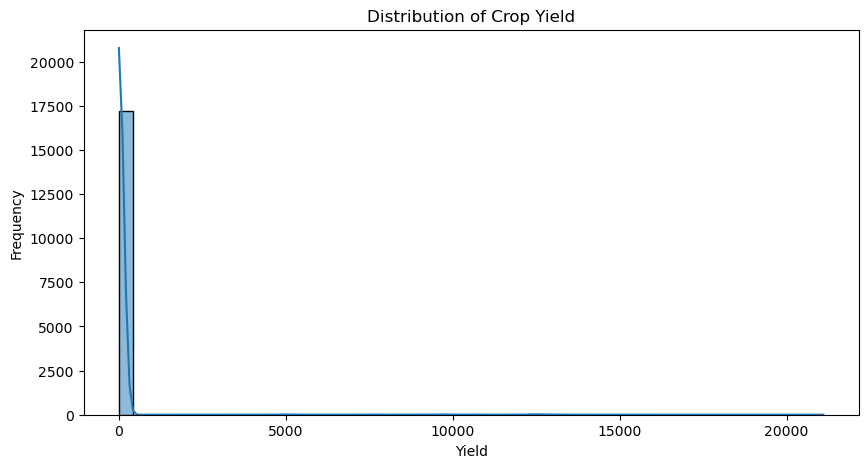

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train_clean["Yield"],
    bins=50,
    kde=True
)

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.show()

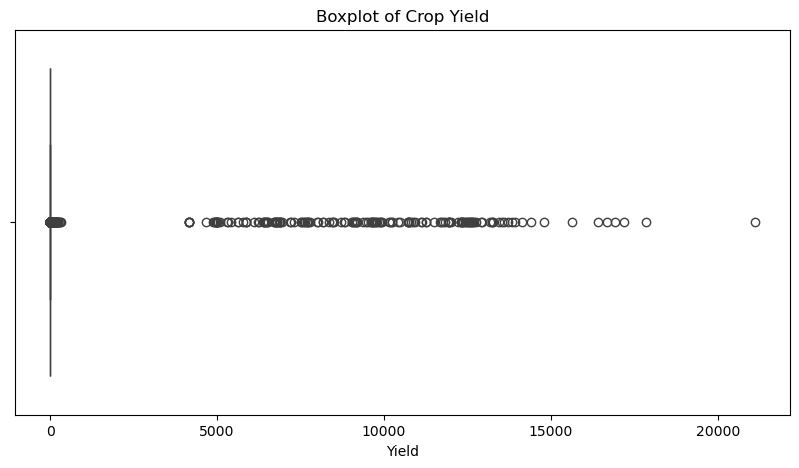

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=train_clean["Yield"]
)

plt.title("Boxplot of Crop Yield")
plt.xlabel("Yield")

plt.show()

# Investigate the high values

In [38]:
train_clean[
    [
        "Year",
        "State",
        "Crop",
        "Season",
        "Area",
        "Annual_Rainfall",
        "Fertilizer",
        "Pesticide",
        "Yield"
    ]
].sort_values(
    "Yield",
    ascending=False
).head(20)

,Year,State,Crop,Season,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
10485,2014,Telangana,Coconut,Whole Year,439.00,746.4,66271.44,144.87,21105.000000
1554,2025,Andhra Pradesh,Coconut,Whole Year,106932.10,1002.6,16956666.45,28117.04,17864.542929
13376,2022,Andhra Pradesh,Coconut,Whole Year,106388.68,909.5,14397537.05,26741.60,17197.142878
2684,2019,Andhra Pradesh,Coconut,Whole Year,104027.00,899.2,17867677.52,38489.99,16935.058460
15060,2021,Andhra Pradesh,Coconut,Whole Year,98130.82,829.2,15030162.07,28193.13,16697.332886
14288,2026,Andhra Pradesh,Coconut,Whole Year,106648.13,956.8,16889927.71,36516.71,16403.433794
17052,2018,Andhra Pradesh,Coconut,Whole Year,104530.00,1220.5,16954766.00,36585.50,15636.632310
2278,2012,Andhra Pradesh,Coconut,Whole Year,99825.00,968.7,15053610.00,30945.75,14794.630000
6521,2012,Puducherry,Coconut,Whole Year,1564.00,1098.3,235851.20,484.84,14410.516670
9253,2009,Tamil Nadu,Coconut,Whole Year,400466.00,928.5,62400612.12,68079.22,14134.659350


In [39]:
# We need to know which crops produce those extreme values before deciding whether they're legitimate or outliers.

# Yield by crop

In [40]:
crop_yield = (
    train_clean
    .groupby("Crop")["Yield"]
    .agg(["mean", "median", "count"])
    .sort_values("median", ascending=False)
)

crop_yield.head(20)

,mean,median,count
Crop,,,
Coconut,8909.195540,9101.813684,179
Sugarcane,56.109922,58.612480,598
Banana,29.940016,25.363826,324
Tomato,23.534134,23.480618,21
Grapes,23.625484,23.292771,19
Tapioca,17.758289,13.003333,187
Onion,14.309768,11.093620,414
Potato,17.341024,10.694371,516
Sweet potato,9.728565,8.514545,251


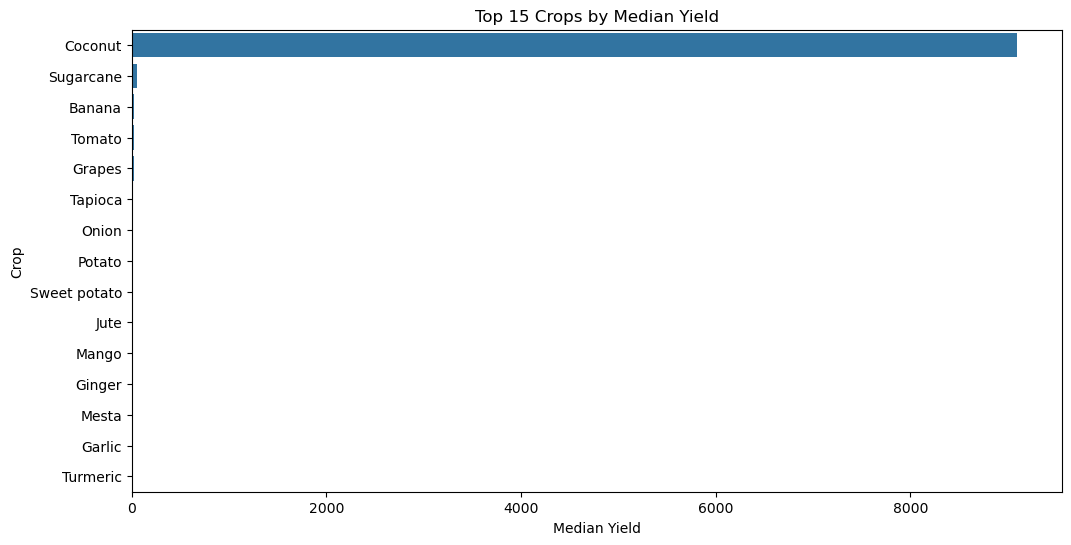

In [41]:
top_crops = crop_yield.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_crops["median"],
    y=top_crops.index
)

plt.title("Top 15 Crops by Median Yield")
plt.xlabel("Median Yield")
plt.ylabel("Crop")

plt.show()

# Why use median instead of mean?

# Because we've already discovered that the target is highly skewed.

# The mean can be heavily influenced by extreme observations.

# Therefore, median is more useful for understanding the typical crop yield during EDA. 

In [42]:
season_yield = (
    train_clean
    .groupby("Season")["Yield"]
    .agg(["mean", "median", "count"])
    .sort_values("median", ascending=False)
)

season_yield

,mean,median,count
Season,,,
Winter,20.638078,9.838815,56
Whole Year,422.353560,5.556364,3905
Summer,7.844322,1.350294,131
Autumn,1.428738,1.088571,389
Kharif,2.794046,0.982971,8684
Rabi,2.251311,0.956829,4235


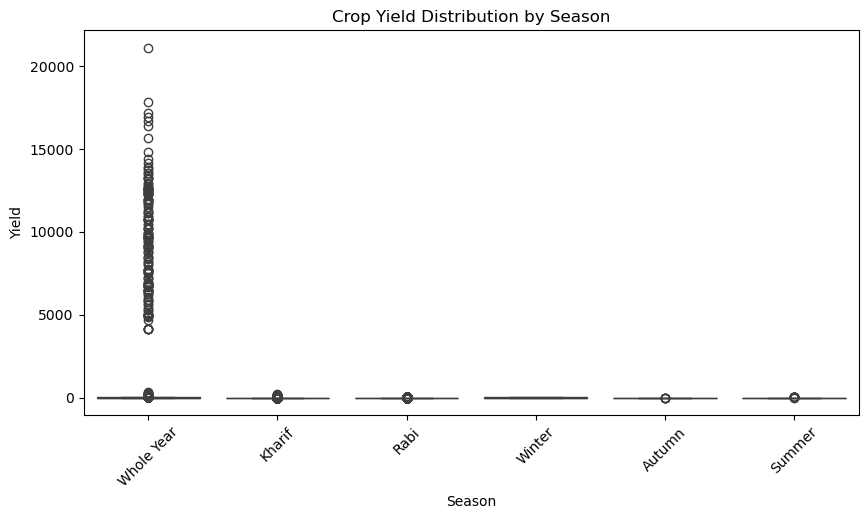

In [43]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_clean,
    x="Season",
    y="Yield"
)

plt.title("Crop Yield Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Yield")

plt.xticks(rotation=45)

plt.show()

# Model Building and Evaluation

In [50]:
# worked from cleanest data
model_data = train_clean.copy()

In [51]:
# Separate input features and target
X = model_data.drop(columns=["Yield"])
y = model_data["Yield"]

print("Dataset shape:", model_data.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values:")
print(model_data.isnull().sum())

print("\nTarget statistics:")
print(y.describe())

Dataset shape: (17400, 9)
Features shape: (17400, 8)
Target shape: (17400,)

Feature columns:
['Year', 'State', 'Crop', 'Season', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Missing values:
Year               0
State              0
Crop               0
Season             0
Area               0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Target statistics:
count    17400.000000
mean        96.886642
std        978.977056
min          0.000000
25%          0.640000
50%          1.098091
75%          2.830957
max      21105.000000
Name: Yield, dtype: float64


# Split training data into training and validation sets

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_valid.shape)

Training features: (13920, 8)
Validation features: (3480, 8)
Training target: (13920,)
Validation target: (3480,)


# Building the preprocessing pipeline

In [54]:
# We'll use one-hot encoding for categorical variables and keep the numerical values unchanged initially.
# The preprocessing will be fitted on training data only, avoiding information leakage from validation data.

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["State", "Crop", "Season"]

numerical_features = ["Year","Area","Annual_Rainfall","Fertilizer","Pesticide"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_features),
        ("numerical","passthrough",numerical_features)]
)
print("Preprocessing pipeline created.")

Preprocessing pipeline created.


# Train and compare your first models

In [56]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_valid)

    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

results_df

,Model,MAE,RMSE,R2
4,Extra Trees,11.556171,152.789240,0.977558
3,Random Forest,12.702856,176.354387,0.970102
2,Decision Tree,14.716771,191.661602,0.964686
0,Baseline,183.188065,1019.913132,-0.000003
1,Linear Regression,182.982886,1019.930080,-0.000037


# Investigating the best model's predictions

In [58]:
# First, let's compare actual and predicted yield values and see whether the model is making large errors.

In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

best_model = trained_models["Extra Trees"]

valid_predictions = best_model.predict(X_valid)

comparison_df = pd.DataFrame({"Actual_Yield": y_valid.values,"Predicted_Yield": valid_predictions})

comparison_df["Absolute_Error"] = (comparison_df["Actual_Yield"] -comparison_df["Predicted_Yield"]).abs()

print("First 10 predictions:")
display(comparison_df.head(10))

print("\nLargest prediction errors:")
display(comparison_df.sort_values("Absolute_Error", ascending=False).head(10))

First 10 predictions:


,Actual_Yield,Predicted_Yield,Absolute_Error
0,9.540000,11.660399,2.120399
1,0.230000,0.176665,0.053335
2,2.936667,2.988511,0.051844
3,0.903333,0.867641,0.035692
4,1.905714,2.184849,0.279135
5,21.500000,19.758386,1.741614
6,17.335000,21.445522,4.110522
7,13.999444,17.809069,3.809625
8,21.954783,16.001016,5.953767
9,0.622519,0.572789,0.049730



Largest prediction errors:


,Actual_Yield,Predicted_Yield,Absolute_Error
2279,9619.110000,13987.376339,4368.266339
192,8363.155000,11117.153646,2753.998646
2384,7717.767778,10411.094388,2693.326610
402,16935.058460,14272.420861,2662.637599
775,17864.542929,15310.960187,2553.582742
2817,10245.722470,12682.451335,2436.728865
3061,8176.517589,10466.076515,2289.558926
1171,9759.512944,7810.816856,1948.696088
677,9678.503667,7813.919981,1864.583686
2075,16697.332886,14879.271730,1818.061156


# Plot actual versus predicted yield

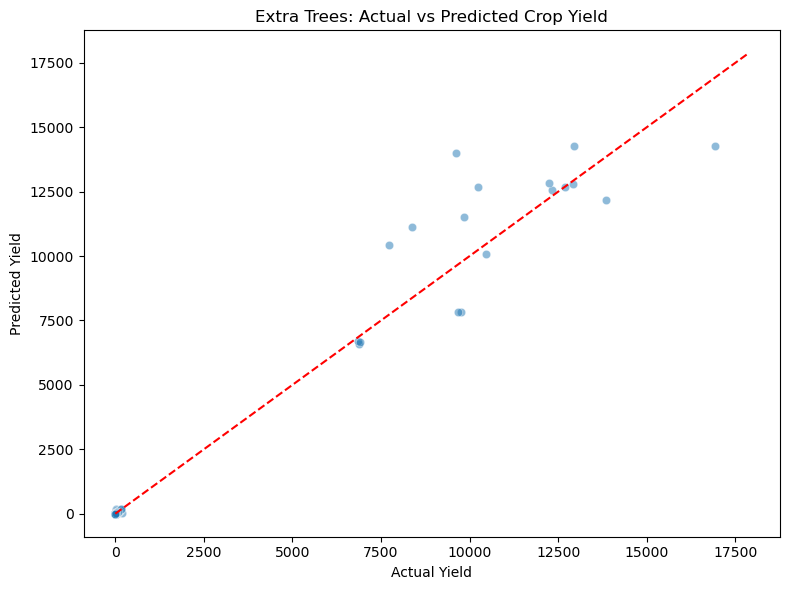

In [61]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=comparison_df.sample(n=min(2000, len(comparison_df)),random_state=42),
    x="Actual_Yield",
    y="Predicted_Yield",
    alpha=0.5
)

limits = [
    min(comparison_df["Actual_Yield"].min(),
        comparison_df["Predicted_Yield"].min()),
    max(comparison_df["Actual_Yield"].max(),
        comparison_df["Predicted_Yield"].max())
]

plt.plot(limits, limits, "r--")
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Extra Trees: Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.show()

# points close to the red diagonal indicate predictions close to actual values.

# Large deviations indicate prediction errors, particularly worth investigating among high-yield observations.

# Checking feature importance

,Feature,Importance
40,categorical__Crop_Coconut,0.844335
4,categorical__State_Chhattisgarh,0.056126
12,categorical__State_Karnataka,0.017310
6,categorical__State_Goa,0.016421
2,categorical__State_Assam,0.012238
101,numerical__Annual_Rainfall,0.011841
99,numerical__Year,0.010267
100,numerical__Area,0.006971
13,categorical__State_Kerala,0.006451
102,numerical__Fertilizer,0.005633


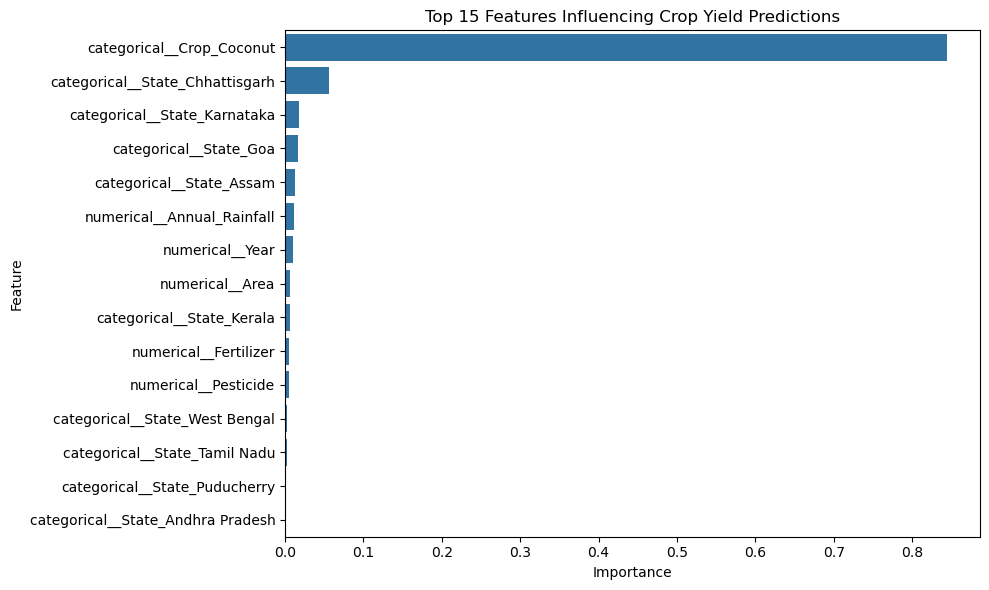

In [62]:
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    best_model.named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Crop Yield Predictions")
plt.tight_layout()
plt.show()

# Checking the test dataset before final evaluation

In [63]:
print("Test shape:", test.shape)
print("Test columns:", test.columns.tolist())

print("\nTest years:")
print(test["Year"].min(), "to", test["Year"].max())

print("\nMissing values:")
print(test.isnull().sum())

print("\nTest yield summary:")
print(test["Yield"].describe())

Test shape: (4350, 10)
Test columns: ['Year', 'State', 'Crop', 'Season', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

Test years:
2000 to 2026

Missing values:
Year               0
State              0
Crop               0
Season             0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Test yield summary:
count     4350.000000
mean        88.760052
std        943.437148
min          0.000000
25%          0.648222
50%          1.130000
75%          2.904188
max      17524.989885
Name: Yield, dtype: float64


# Checking the target variable and extreme values

In [64]:
# Checking the distribution of the target variable
print(train_clean["Yield"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

print("Zero-yield records:",
      (train_clean["Yield"] == 0).sum())

print("Negative-yield records:",
      (train_clean["Yield"] < 0).sum())

# Inspect the 20 highest-yield observations
display(
    train_clean.sort_values(
        "Yield", ascending=False
    ).head(20)
)

count    17400.000000
mean        96.886642
std        978.977056
min          0.000000
50%          1.098091
75%          2.830957
90%         12.821630
95%         28.844809
99%        242.671451
max      21105.000000
Name: Yield, dtype: float64
Zero-yield records: 77
Negative-yield records: 0


,Year,State,Crop,Season,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
10485,2014,Telangana,Coconut,Whole Year,439.00,746.4,66271.44,144.87,21105.000000
1554,2025,Andhra Pradesh,Coconut,Whole Year,106932.10,1002.6,16956666.45,28117.04,17864.542929
13376,2022,Andhra Pradesh,Coconut,Whole Year,106388.68,909.5,14397537.05,26741.60,17197.142878
2684,2019,Andhra Pradesh,Coconut,Whole Year,104027.00,899.2,17867677.52,38489.99,16935.058460
15060,2021,Andhra Pradesh,Coconut,Whole Year,98130.82,829.2,15030162.07,28193.13,16697.332886
14288,2026,Andhra Pradesh,Coconut,Whole Year,106648.13,956.8,16889927.71,36516.71,16403.433794
17052,2018,Andhra Pradesh,Coconut,Whole Year,104530.00,1220.5,16954766.00,36585.50,15636.632310
2278,2012,Andhra Pradesh,Coconut,Whole Year,99825.00,968.7,15053610.00,30945.75,14794.630000
6521,2012,Puducherry,Coconut,Whole Year,1564.00,1098.3,235851.20,484.84,14410.516670
9253,2009,Tamil Nadu,Coconut,Whole Year,400466.00,928.5,62400612.12,68079.22,14134.659350


# Checking whether the model generalizes

In [65]:
# Check how many unique crops and states occur
# in training and validation data

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

print("Training crops:",
      X_train["Crop"].nunique())

print("Validation crops:",
      X_valid["Crop"].nunique())

print("Training states:",
      X_train["State"].nunique())

print("Validation states:",
      X_valid["State"].nunique())

Training rows: 13920
Validation rows: 3480
Training crops: 62
Validation crops: 62
Training states: 31
Validation states: 31


In [66]:
# This assumes X_train and X_valid are the original, unprocessed DataFrames and still contain Crop and State.
# If you used different variable names, adapt them to your notebook.

# Tuneing the Extra Trees model

In [67]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Tune the existing Extra Trees pipeline
param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=best_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

tuned_model = random_search.best_estimator_

print("Best parameters:")
print(random_search.best_params_)

print("Best CV RMSE:",
      -random_search.best_score_)

valid_predictions = tuned_model.predict(X_valid)

print("Validation MAE:",
      mean_absolute_error(y_valid, valid_predictions))

print("Validation RMSE:",
      np.sqrt(mean_squared_error(y_valid, valid_predictions)))

print("Validation R²:",
      r2_score(y_valid, valid_predictions))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 35}
Best CV RMSE: 146.04731675042441
Validation MAE: 10.546060839991403
Validation RMSE: 143.9030096150077
Validation R²: 0.9800925870499889


In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use exactly the same input columns as the training data
feature_cols = list(X_train.columns)

print("Features used during training:")
print(feature_cols)

# Check whether all required columns exist in test data
missing_cols = set(feature_cols) - set(test.columns)
print("\nMissing test columns:", missing_cols)

if missing_cols:
    print("STOP: Resolve missing columns before evaluating.")
else:
    X_test = test[feature_cols].copy()
    y_test = test["Yield"]

    # Predict using the tuned pipeline
    test_predictions = tuned_model.predict(X_test)

    print("\nFINAL TEST RESULTS")
    print("------------------")
    print("MAE:", round(mean_absolute_error(
        y_test, test_predictions
    ), 4))

    print("RMSE:", round(np.sqrt(mean_squared_error(
        y_test, test_predictions
    )), 4))

    print("R²:", round(r2_score(
        y_test, test_predictions
    ), 4))

    # Examine the largest errors
    test_results = pd.DataFrame({
        "Actual_Yield": y_test.to_numpy(),
        "Predicted_Yield": test_predictions
    })

    test_results["Absolute_Error"] = (
        test_results["Actual_Yield"]
        - test_results["Predicted_Yield"]
    ).abs()

    display(
        test_results
        .sort_values("Absolute_Error", ascending=False)
        .head(10)
    )

Features used during training:
['Year', 'State', 'Crop', 'Season', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

Missing test columns: set()

FINAL TEST RESULTS
------------------
MAE: 8.2853
RMSE: 115.6462
R²: 0.985


,Actual_Yield,Predicted_Yield,Absolute_Error
2550,16254.000000,21105.000000,4851.000000
1003,10564.982739,12717.413878,2152.431139
3758,17524.989885,15587.538735,1937.451150
3224,11343.011810,9542.753438,1800.258372
4059,9156.942222,7422.912581,1734.029641
1056,8735.670741,7194.839671,1540.831070
1508,9474.625000,10886.377582,1411.752582
3178,11907.645810,10501.390063,1406.255747
2816,6359.690000,5088.429888,1271.260112
878,12333.935779,11154.132736,1179.803043


In [69]:
print("MAE:", mean_absolute_error(y_test, test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("R2:", r2_score(y_test, test_predictions))

error_check = pd.DataFrame({
    "Actual_Yield": y_test.values,
    "Predicted_Yield": test_predictions
})

error_check["Absolute_Error"] = (
    error_check["Actual_Yield"] -
    error_check["Predicted_Yield"]
).abs()

display(
    error_check.sort_values(
        "Absolute_Error", ascending=False
    ).head(15)
)

MAE: 8.285338636161182
RMSE: 115.64616567967556
R2: 0.9849707821308816


,Actual_Yield,Predicted_Yield,Absolute_Error
2550,16254.000000,21105.000000,4851.000000
1003,10564.982739,12717.413878,2152.431139
3758,17524.989885,15587.538735,1937.451150
3224,11343.011810,9542.753438,1800.258372
4059,9156.942222,7422.912581,1734.029641
1056,8735.670741,7194.839671,1540.831070
1508,9474.625000,10886.377582,1411.752582
3178,11907.645810,10501.390063,1406.255747
2816,6359.690000,5088.429888,1271.260112
878,12333.935779,11154.132736,1179.803043


In [70]:
display(
    train_clean.groupby("Crop")["Yield"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("max", ascending=False)
    .head(15)
)

,count,mean,median,max
Crop,,,,
Coconut,179,8909.195540,9101.813684,21105.000000
Cashewnut,147,3.120205,0.466667,338.548966
Potato,516,17.341024,10.694371,311.020000
Onion,414,14.309768,11.093620,247.572727
Sugarcane,598,56.109922,58.612480,197.007388
Banana,324,29.940016,25.363826,126.387692
other oilseeds,132,5.679480,0.761143,103.530912
Tobacco,325,2.105684,1.266156,57.120500
Tapioca,187,17.758289,13.003333,49.981493


# Validate the final test results 

In [72]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Make sure these are the final test targets and predictions
actual = np.asarray(y_test).ravel()
predicted = np.asarray(test_predictions).ravel()

print("Number of actual values:", len(actual))
print("Number of predictions:", len(predicted))

assert len(actual) == len(predicted), (
    "Actual values and predictions have different lengths."
)

# Recalculate every metric from the same arrays
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

print("\nCONSISTENT FINAL TEST METRICS")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# Create the error table from those same arrays
error_check = pd.DataFrame({
    "Actual_Yield": actual,
    "Predicted_Yield": predicted
})

error_check["Absolute_Error"] = (
    error_check["Actual_Yield"] -
    error_check["Predicted_Yield"]
).abs()

print("\nLargest prediction errors:")
display(
    error_check
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

print("\nMAE calculated directly from error table:",
      error_check["Absolute_Error"].mean())

Number of actual values: 4350
Number of predictions: 4350

CONSISTENT FINAL TEST METRICS
MAE:  8.2853
RMSE: 115.6462
R²:   0.9850

Largest prediction errors:


,Actual_Yield,Predicted_Yield,Absolute_Error
2550,16254.000000,21105.000000,4851.000000
1003,10564.982739,12717.413878,2152.431139
3758,17524.989885,15587.538735,1937.451150
3224,11343.011810,9542.753438,1800.258372
4059,9156.942222,7422.912581,1734.029641
1056,8735.670741,7194.839671,1540.831070
1508,9474.625000,10886.377582,1411.752582
3178,11907.645810,10501.390063,1406.255747
2816,6359.690000,5088.429888,1271.260112
878,12333.935779,11154.132736,1179.803043



MAE calculated directly from error table: 8.285338636161182


# Saving tuned model

In [73]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    tuned_model,
    "models/crop_yield_model.pkl"
)

print("Saved: models/crop_yield_model.pkl")

Saved: models/crop_yield_model.pkl


# Confirming that the saved model loads correctly

In [75]:
loaded_model = joblib.load(
    "models/crop_yield_model.pkl"
)

check_predictions = loaded_model.predict(X_valid)

print("Model loaded successfully.")
print("Sample predictions:", check_predictions[:5])

Model loaded successfully.
Sample predictions: [11.56056461  0.73082683  2.96656196  0.84809096  2.17661712]


# Export the crop, state and season choices

In [76]:
import json
import os

os.makedirs("models", exist_ok=True)

app_options = {
    "State": sorted(
        train_clean["State"].dropna().astype(str).unique().tolist()
    ),
    "Crop": sorted(
        train_clean["Crop"].dropna().astype(str).unique().tolist()
    ),
    "Season": sorted(
        train_clean["Season"].dropna().astype(str).unique().tolist()
    ),
    "Year_min": int(train_clean["Year"].min()),
    "Year_max": int(train_clean["Year"].max())
}

with open("models/app_options.json", "w", encoding="utf-8") as f:
    json.dump(app_options, f, indent=2)

print("Application options saved successfully.")

Application options saved successfully.
